<div style="background-color:#1F3864; padding:25px; border-radius:8px;">
<h1 style="color:white; text-align:center; margin:0;">Online Retail II: Customer Churn</h1>
<p style="color:#D9E2F3; text-align:center; margin-top:10px; font-size:15px;">Exploratory Data Analysis &amp; Data Cleaning |  online retailer, Dec 2009 – Dec 2011</p>
</div>

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

<div style="background-color:#EDCC80; padding:15px; border-radius:8px;">
<h2 style="color:#1F3864; text-align:center; margin:0;">1. Loading the Data</h2>
</div>

<div style="background-color:#EDEAE5; padding:10px 15px; border-radius:6px;">
<h3 style="color:#1F3864; text-align:center; margin:0;">1.1 Imports</h3>
</div>

In [3]:
data = pd.read_csv("../data/raw/online_retail_II.csv")

<div style="background-color:#EDCC80; padding:15px; border-radius:8px;">
<h2 style="color:#1F3864; text-align:center; margin:0;">2. Data Structure</h2>
</div>

<div style="background-color:#EDEAE5; padding:10px 15px; border-radius:6px;">
<h3 style="color:#1F3864; text-align:center; margin:0;">2.1 Missing values</h3>
</div>

In [4]:
data.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

### Observation: missing values

- **Customer ID** is missing in **243,007 rows (~22.8%)**. These transactions can't be linked to a customer, so they can't be used for churn analysis and will be **dropped**.
- **Description** is missing in **4,382 rows (~0.4%)**. This is small, and many of these rows likely also have no Customer ID, so most will disappear when those rows are dropped.
- All other columns (Invoice, StockCode, Quantity, InvoiceDate, Price, Country) have **no missing values**.

<div style="background-color:#EDEAE5; padding:10px 15px; border-radius:6px;">
<h3 style="color:#1F3864; text-align:center; margin:0;">2.2 Data Distribution</h3>
</div>

In [5]:
data.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


### Observation: summary statistics

- **Quantity:** the median is **3** units per line and 75% of lines are **10 units or fewer**, but the range is extreme: from **−80,995 to +80,995**. The matching size suggests one huge order that was later **cancelled**. Negative quantities represent cancellations and returns.
- **Price:** the median unit price is **£2.10** and 75% are **≤ £4.15** (low-cost gift items), but the min is **−£53,594** and the max is **£38,970**. These are not real products; they look like **accounting adjustments** (e.g. bad-debt entries or manual charges).
- **Mean ≫ median** for both columns (Quantity 9.9 vs 3, Price 4.65 vs 2.10), so the distributions are **heavily right-skewed** with extreme outliers.
- **Customer ID** statistics are not meaningful (it's an identifier, not a quantity). Only its count matters: **824,364 of 1,067,371** rows have one (**22.8% missing**).
- **Cleaning needed:** remove negative quantities and prices, investigate the extreme values, and drop rows without a Customer ID.

<div style="background-color:#EDEAE5; padding:10px 15px; border-radius:6px;">
<h3 style="color:#1F3864; text-align:center; margin:0;">2.3 Check for Outliers</h3>
</div>

In [6]:
q1 = data['Price'].quantile(0.25)
q3 = data['Price'].quantile(0.75)
IQR = q3 - q1

lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

outliers = data[(data['Price'] < lower_bound) | (data['Price'] > upper_bound)]
print("Outliers:\n ")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
outliers

Outliers:
 
Lower Bound: -3.10
Upper Bound: 8.50


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
35,489437,21360,JOY LARGE WOOD LETTERS,1,2009-12-01 09:08:00,9.95,15362.0,United Kingdom
38,489437,35400,WOODEN BOX ADVENT CALENDAR,2,2009-12-01 09:08:00,8.95,15362.0,United Kingdom
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.00,12682.0,France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.0,USA
131,489445,22180,RETRO SPOT LAMP,2,2009-12-01 09:57:00,9.95,17519.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067229,581578,POST,POSTAGE,3,2011-12-09 12:16:00,18.00,12713.0,Germany
1067247,581578,22622,BOX OF VINTAGE ALPHABET BLOCKS,6,2011-12-09 12:16:00,11.95,12713.0,Germany
1067313,581580,22894,TABLECLOTH RED APPLES DESIGN,2,2011-12-09 12:20:00,9.95,12748.0,United Kingdom
1067353,581586,21217,RED RETROSPOT ROUND CAKE TINS,24,2011-12-09 12:49:00,8.95,13113.0,United Kingdom


<Axes: >

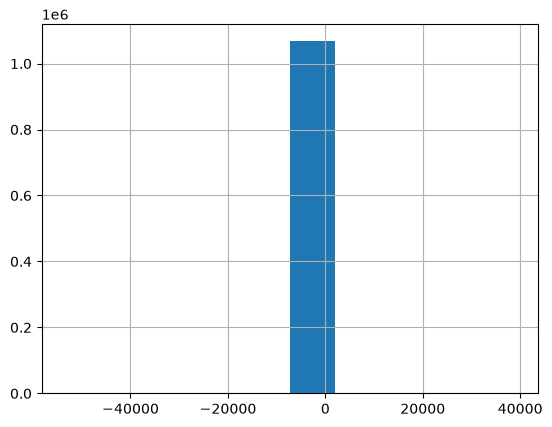

In [7]:
data['Price'].hist()

### Outlier Analysis: Price

Using the IQR method (1.5 × IQR), the bounds for `Price` are **-3.10** (lower) and **8.50** (upper), which flags **68,105 rows** as outliers.

However, these are mostly **not true outliers**:
- `Price` is heavily **right-skewed**: most products cost a few pounds, so the IQR range is narrow.
- Many flagged rows are ordinary products priced just above the bound (e.g. 9.95, 11.95).
- The histogram is dominated by a few extreme values (roughly -50,000 to +40,000), which compresses all normal prices into a single bar near zero.

**Decision:** the IQR rule is not suitable for this column. Instead of dropping the 68k flagged rows, the next step is to inspect the extreme values directly (prices ≤ 0 and the highest prices) and check whether they are non-product entries (e.g. postage, manual adjustments, fees) rather than real sales.

In [8]:
q1 = data['Quantity'].quantile(0.25)
q3 = data['Quantity'].quantile(0.75)
IQR = q3 - q1

lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

outliers = data[(data['Quantity'] < lower_bound) | (data['Quantity'] > upper_bound)]
print("Outliers:\n ")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
outliers

Outliers:
 
Lower Bound: -12.50
Upper Bound: 23.50


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
10,489435,22195,HEART MEASURING SPOONS LARGE,24,2009-12-01 07:46:00,1.65,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067337,581585,84945,MULTI COLOUR SILVER T-LIGHT HOLDER,24,2011-12-09 12:31:00,0.85,15804.0,United Kingdom
1067343,581585,21916,SET 12 RETRO WHITE CHALK STICKS,24,2011-12-09 12:31:00,0.42,15804.0,United Kingdom
1067344,581585,84692,BOX OF 24 COCKTAIL PARASOLS,25,2011-12-09 12:31:00,0.42,15804.0,United Kingdom
1067352,581586,23275,SET OF 3 HANGING OWLS OLLIE BEAK,24,2011-12-09 12:49:00,1.25,13113.0,United Kingdom


<Axes: >

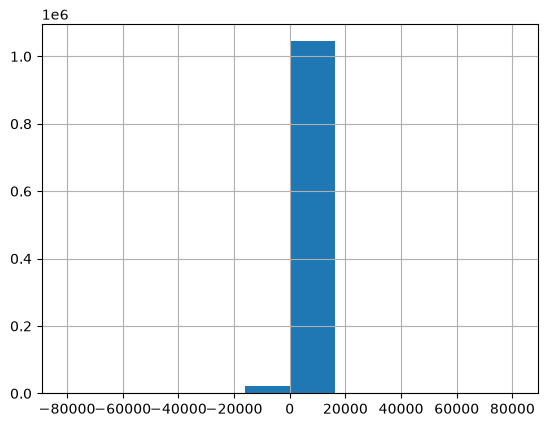

In [9]:
data["Quantity"].hist()

In [10]:
data['Quantity'].describe()
data.sort_values('Quantity').head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
303996,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.00,NaN,United Kingdom
750990,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
750991,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
529729,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0,United Kingdom
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0,United Kingdom
156488,504311,22197,NaN,-9200,2010-04-12 14:39:00,0.00,NaN,United Kingdom
750989,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,0.00,NaN,United Kingdom
428975,530348,16235,?,-9000,2010-11-02 15:48:00,0.00,NaN,United Kingdom


In [11]:
data.sort_values('Quantity').tail(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,0.00,NaN,United Kingdom
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


### Outlier Analysis: Quantity

Using the IQR method (1.5 × IQR), the bounds for `Quantity` are **-12.50** (lower) and **23.50** (upper), which flags **116,489 rows** as outliers.

However, these are mostly **not true outliers**:
- The store sells largely to **wholesalers**, who buy in packs (12, 24, 48…), so an order of 24 units is normal.
- `Quantity` is heavily skewed, which makes the IQR range too narrow for this data.

Inspecting the extreme values directly shows three different cases:

1. **Mistaken orders that were cancelled:** two very large orders were placed and reversed within minutes by a matching cancellation:
   - 80,995 × "PAPER CRAFT, LITTLE BIRDIE" (invoice 581483 → cancelled by C581484)
   - 74,215 × "MEDIUM CERAMIC TOP STORAGE JAR" (invoice 541431 → cancelled by C541433)

   → Both the orders and their cancellations will be **dropped**, since they don't reflect real purchases.

2. **Stock write-offs:** large negative quantities with price 0, no Customer ID, and descriptions like "printing smudges/thrown away", "?", or missing.
   → These are warehouse adjustments, not sales, and will be removed by the `Price > 0` and missing Customer ID filters.

3. **Genuine wholesale orders:** large orders (10,000–19,000 units) with real customers, real products and no cancellation (e.g. customer 13902 in Denmark).
   → **Kept**, as they represent real customer behavior.

**Decision:** rows are removed based on a specific reason, not on quantity size. Normal returns (negative quantity with a positive price) are kept.

<div style="background-color:#EDEAE5; padding:10px 15px; border-radius:6px;">
<h3 style="color:#1F3864; text-align:center; margin:0;">2.4 Check for duplicates</h3>
</div>

In [12]:
duplicates = data.duplicated()
print(duplicates.sum())

34335


In [13]:
data = data.drop_duplicates()
data.shape

(1033036, 8)

<div style="background-color:#EDCC80; padding:15px; border-radius:8px;">
<h2 style="color:#1F3864; text-align:center; margin:0;">3. Explanatory Data Analysis</h2>
</div>

In [14]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


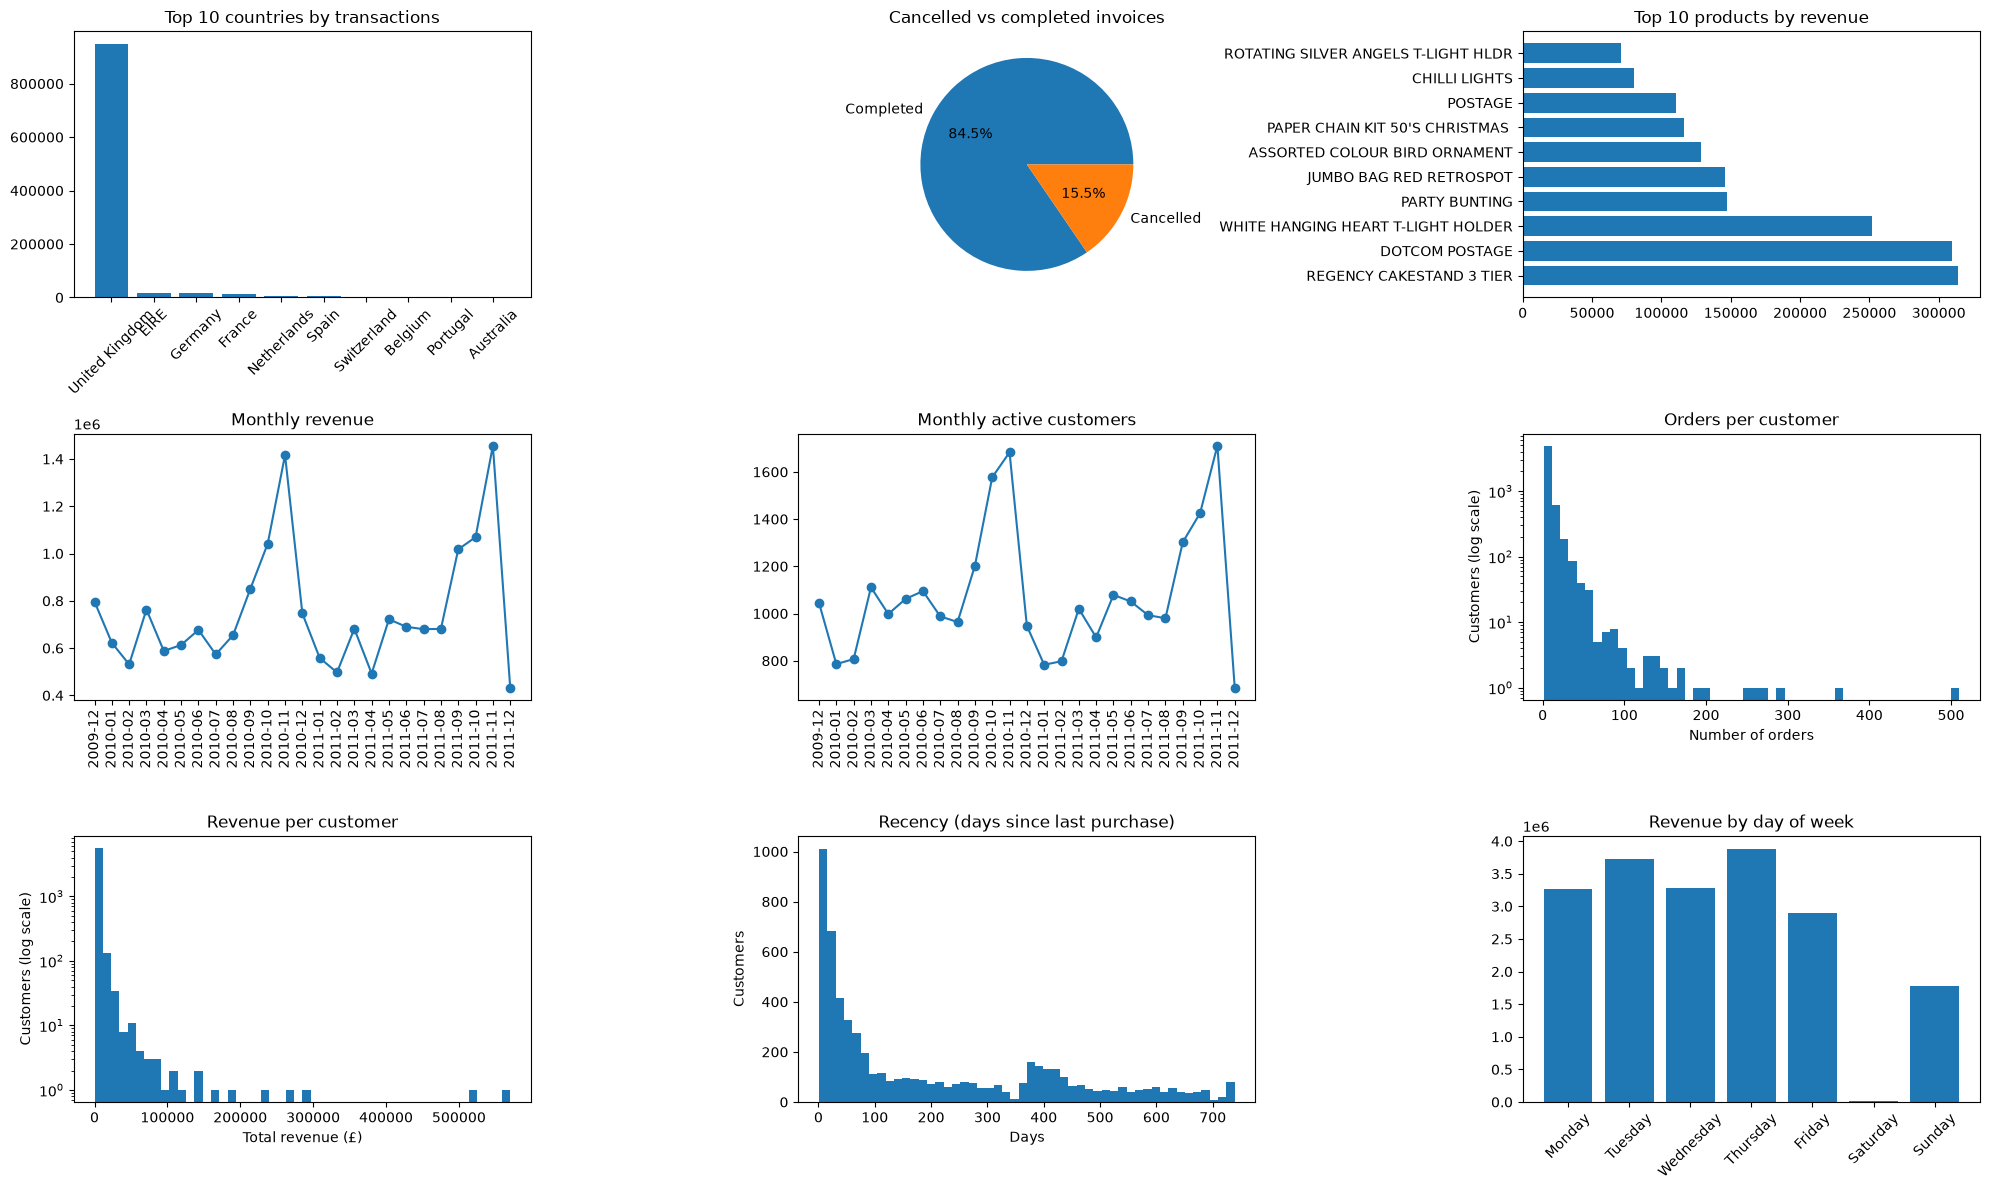

In [29]:
fig,ax = plt.subplots(3,3,figsize = (20,12))
ax = ax.flatten()

country_count = data["Country"].value_counts()
top = country_count.head(10)
ax[0].bar(top.index, top.values)
ax[0].tick_params(axis='x', rotation=45)
ax[0].set_title("Top 10 countries by transactions")

invoices = pd.Series(data["Invoice"].astype(str).unique())
cancelled = invoices.str.startswith("C")
counts = cancelled.value_counts()
ax[1].pie(counts, labels=["Completed", "Cancelled"], autopct="%1.1f%%")
ax[1].set_title("Cancelled vs completed invoices")

des = data.groupby("Description")["revenue"].sum().sort_values(ascending=False).head(10)
ax[2].barh(des.index, des.values)
ax[2].invert_yaxis
ax[2].set_title("Top 10 products by revenue")

data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
monthly_rev = data.groupby(data["InvoiceDate"].dt.to_period("M"))["revenue"].sum()
ax[3].plot(monthly_rev.index.astype(str), monthly_rev.values, marker="o")
ax[3].set_title("Monthly revenue")
ax[3].tick_params(axis="x", rotation=90)

monthly_active = data.groupby(data["InvoiceDate"].dt.to_period("M"))["Customer ID"].nunique()
ax[4].plot(monthly_active.index.astype(str), monthly_active.values, marker="o")
ax[4].set_title("Monthly active customers")
ax[4].tick_params(axis="x", rotation=90)

orders_per_cust = data.groupby("Customer ID")["Invoice"].nunique()
ax[5].hist(orders_per_cust, bins=50)
ax[5].set_yscale("log")
ax[5].set_title("Orders per customer")
ax[5].set_xlabel("Number of orders")
ax[5].set_ylabel("Customers (log scale)")

rev_per_cust = data.groupby("Customer ID")["revenue"].sum()
rev_per_cust = rev_per_cust[rev_per_cust > 0]
ax[6].hist(rev_per_cust, bins=50)
ax[6].set_yscale("log")
ax[6].set_title("Revenue per customer")
ax[6].set_xlabel("Total revenue (£)")
ax[6].set_ylabel("Customers (log scale)")

ref_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)
last_purchase = data.groupby("Customer ID")["InvoiceDate"].max()
recency = (ref_date - last_purchase).dt.days
ax[7].hist(recency, bins=50)
ax[7].set_title("Recency (days since last purchase)")
ax[7].set_xlabel("Days")
ax[7].set_ylabel("Customers")

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
rev_by_day = data.groupby(data["InvoiceDate"].dt.day_name())["revenue"].sum().reindex(days)
ax[8].bar(rev_by_day.index, rev_by_day.values)
ax[8].set_title("Revenue by day of week")
ax[8].tick_params(axis="x", rotation=45)

plt.tight_layout()

## 3. Exploratory Analysis: Key Findings

**Countries**
- The **United Kingdom** dominates, with the large majority of transactions. Other countries (EIRE, Germany, France, Netherlands…) each make up only a small share.
- Any conclusions are therefore mostly about UK customers.

**Cancellations**
- **15.5% of invoices are cancellations.** That's a substantial share, so return behavior could be a useful churn signal.

**Top products**
- The top sellers are home and party items (cake stand, T-light holder, bunting, Christmas decorations).
- **"DOTCOM POSTAGE" and "POSTAGE" appear in the top 10.** These are shipping charges, not products, and will be removed in cleaning.

**Seasonality**
- Revenue and active customers both **peak sharply in November** in 2010 and 2011, driven by Christmas buying.
- The two curves move together, so revenue growth comes mainly from **more customers buying**, not from customers spending more per order.
- The drop in **December 2011 is not real**: the data ends on 9 Dec 2011, so that month is incomplete.

**Customer behavior**
- **Orders per customer** and **revenue per customer** are both highly right-skewed: most customers buy a few times and spend little, while a small number of wholesalers place hundreds of orders and generate very high revenue.
- These skewed features will likely need a **log transform** before modeling.

**Recency**
- Many customers purchased recently, but there's a **long tail** of customers who haven't bought in months. These are potential churners.
- A **second bump around 365–400 days** suggests customers who bought during the 2010 Christmas season and didn't return, i.e. likely **seasonal buyers**.

**Day of week**
- Sales happen on all days **except Saturday**, which has almost no revenue (the store appears not to trade on Saturdays).
- Thursday and Tuesday are the strongest days.

**Implications for the churn model**
- Seasonality matters: the churn window should account for customers who only buy around Christmas.
- Recency, frequency and monetary value (RFM) show clear variation across customers, which makes them promising features.

In [31]:
kpis = {
    "Total revenue": f"£{revenue:,.0f}",
    "Customers": f"{n_customers:,}",
    "Orders": f"{n_orders:,}",
    "Avg order value": f"£{aov:,.2f}",
    "Revenue per customer": f"£{rev_per_customer:,.2f}",
    "Repeat customer rate": f"{repeat_rate:.1f}%",
    "Cancellation rate": "15.5%",
}

fig, ax = plt.subplots(2, 4, figsize=(16, 6))
ax = ax.flatten()

for i, (name, value) in enumerate(kpis.items()):
    ax[i].text(0.5, 0.6, value, ha="center", va="center", fontsize=24, fontweight="bold")
    ax[i].text(0.5, 0.3, name, ha="center", va="center", fontsize=12, color="gray")
    ax[i].set_xticks([])
    ax[i].set_yticks([])

ax[7].axis("off")  # 7 KPIs, so the 8th slot stays empty

fig.suptitle("KPIs", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

TypeError: unsupported format string passed to Series.__format__